# Air quality and weather for a place and time (Open-Meteo)

Pipeline for HazeWise: give it a latitude, longitude and a local date/time (now or in the future), get back the US AQI,
PM2.5 and the weather for that hour.

```
get_conditions(lat, lon, when)  ->  {aqi_us, aqi_category, pm25_ugm3, temp_c, apparent_temp_c, humidity_pct,
                                     wind_speed_ms, precip_prob_pct, weather, thunderstorm, ...}
conditions_timeline(lat, lon)   ->  hourly DataFrame with the same columns
```

Everything comes from Open-Meteo, unchanged:

* [Air quality API](https://open-meteo.com/en/docs/air-quality-api): PM2.5, PM10 and US AQI from the CAMS global
  forecast (0.4°, about 45 km grid, new run every 12 h, 5-day horizon). Open-Meteo's US AQI uses a 24 h rolling
  average for PM2.5 and PM10.
* [Weather forecast API](https://open-meteo.com/en/docs): temperature, humidity, apparent temperature, rain,
  wind, pressure, cloud, UV. Best-match global models, 16-day horizon.

"Now" uses each API's `current` block. Future times use the `hourly` forecast at the nearest hour. The pipeline adds
three lookups and nothing else: the EPA category name for the AQI, the WMO text for the weather code, and the main
pollutant (the component with the highest US AQI sub-index, which is what Open-Meteo's `us_aqi` takes as its value).
No key needed.

Data attribution, as Open-Meteo requires: weather data by [Open-Meteo.com](https://open-meteo.com/); air quality
from the Copernicus Atmosphere Monitoring Service (CAMS ENSEMBLE data provider).

In [1]:
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

OM_AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
OM_WX_URL = "https://api.open-meteo.com/v1/forecast"
EAST_COAST_PARK = (1.3010, 103.9120)

# chart tokens (light mode), same as explore.ipynb
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "figure.dpi": 110, "font.family": ["Helvetica Neue", "Helvetica", "Arial", "sans-serif"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "lines.linewidth": 1.8,
    "axes.prop_cycle": plt.cycler(color=C), "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": INK2,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## 1. Open-Meteo client

Both APIs are called with `timezone=auto` (time zone of the coordinates) and `timeformat=unixtime`, then converted
to that zone, which makes DST safe. Errors come back as HTTP 400 with a `reason` and are raised as `OpenMeteoError`.
Responses are cached per rounded coordinate and UTC hour.

In [2]:
AQ_VARS = ["pm2_5", "pm10", "us_aqi", "us_aqi_pm2_5", "us_aqi_pm10", "us_aqi_ozone", "us_aqi_nitrogen_dioxide",
           "us_aqi_sulphur_dioxide", "us_aqi_carbon_monoxide"]
WX_VARS = ["temperature_2m", "relative_humidity_2m", "apparent_temperature", "precipitation_probability",
           "precipitation", "weather_code", "wind_speed_10m", "wind_gusts_10m", "wind_direction_10m",
           "surface_pressure", "cloud_cover", "uv_index", "is_day"]


class OpenMeteoError(RuntimeError):
    pass


_cache = {}


def om_fetch(url, lat, lon, variables, **extra):
    # returns (current: dict, hourly: DataFrame indexed by local time, meta: dict)
    k = (url, round(lat, 3), round(lon, 3), pd.Timestamp.now(tz="UTC").floor("h"))
    if k not in _cache:
        params = dict(latitude=lat, longitude=lon, current=",".join(variables), hourly=",".join(variables),
                      timezone="auto", timeformat="unixtime", **extra)
        r = requests.get(url, params=params, timeout=20)
        body = r.json()
        if r.status_code != 200 or body.get("error"):
            raise OpenMeteoError(body.get("reason", f"HTTP {r.status_code}"))
        tz = ZoneInfo(body["timezone"])
        hourly = pd.DataFrame(body["hourly"])
        hourly.index = pd.to_datetime(hourly.pop("time"), unit="s", utc=True).dt.tz_convert(tz)
        hourly.index.name = "time"
        current = dict(body["current"])
        current["time"] = pd.Timestamp(current["time"], unit="s", tz="UTC").tz_convert(tz)
        meta = {k: body[k] for k in ("latitude", "longitude", "timezone", "elevation")}
        _cache[k] = (current, hourly, meta)
    return _cache[k]


def om_air_quality(lat, lon):
    return om_fetch(OM_AQ_URL, lat, lon, AQ_VARS, forecast_days=7)


def om_weather(lat, lon):
    return om_fetch(OM_WX_URL, lat, lon, WX_VARS, forecast_days=16, wind_speed_unit="ms")

In [3]:
aq_now, aq, aq_meta = om_air_quality(*EAST_COAST_PARK)
wx_now, wx, wx_meta = om_weather(*EAST_COAST_PARK)
print(f"time zone {wx_meta['timezone']}")
print(f"air quality grid point {aq_meta['latitude']:.2f}, {aq_meta['longitude']:.2f}; "
      f"weather grid point {wx_meta['latitude']:.2f}, {wx_meta['longitude']:.2f}")
print(f"air quality forecast has values until {aq.us_aqi.last_valid_index():%a %d %b %H:%M}")
print(f"weather forecast runs until {wx.temperature_2m.last_valid_index():%a %d %b %H:%M}")
display(pd.DataFrame({"air quality (current)": pd.Series(aq_now), "weather (current)": pd.Series(wx_now)}))

time zone Asia/Singapore
air quality grid point 1.30, 103.90; weather grid point 1.30, 103.86
air quality forecast has values until Wed 21 Oct 21:00
weather forecast runs until Sun 01 Nov 23:00


,air quality (current),weather (current)
apparent_temperature,NaN,36.4
cloud_cover,NaN,15
interval,3600,900
is_day,NaN,1
pm10,75.7,NaN
pm2_5,69.2,NaN
precipitation,NaN,0.1
precipitation_probability,NaN,76
relative_humidity_2m,NaN,60
surface_pressure,NaN,1008.7


## 2. The pipeline

`conditions_timeline` joins the hourly weather and air quality tables and renames columns to the output schema.
`get_conditions` picks one time from it:

* **Now** (within 30 min of the current time): the `current` blocks. Weather is a 15-minute value, air quality hourly.
* **Future**: the hourly forecast at the nearest hour.
* **Past the air quality horizon** (about 4.5 days): weather only. AQI fields are `None` and `aq_note` says why.
* **Past times, or past the 16-day weather horizon**: `ValueError`.

Naive datetimes are read as local time at the coordinates. Time-zone-aware datetimes are converted.

In [4]:
AQI_CATEGORIES = [(50, "Good"), (100, "Moderate"), (150, "Unhealthy for sensitive groups"), (200, "Unhealthy"),
                  (300, "Very unhealthy"), (float("inf"), "Hazardous")]
WMO_CODES = {0: "clear sky", 1: "mainly clear", 2: "partly cloudy", 3: "overcast", 45: "fog", 48: "rime fog",
             51: "light drizzle", 53: "drizzle", 55: "dense drizzle", 56: "freezing drizzle", 57: "freezing drizzle",
             61: "slight rain", 63: "moderate rain", 65: "heavy rain", 66: "freezing rain", 67: "freezing rain",
             71: "slight snow", 73: "snow", 75: "heavy snow", 77: "snow grains", 80: "slight showers",
             81: "showers", 82: "violent showers", 85: "snow showers", 86: "snow showers", 95: "thunderstorm",
             96: "thunderstorm with hail", 99: "thunderstorm with hail"}
AQ_RENAME = {"us_aqi": "aqi_us", "pm2_5": "pm25_ugm3", "pm10": "pm10_ugm3"}
WX_RENAME = {"temperature_2m": "temp_c", "apparent_temperature": "apparent_temp_c", "relative_humidity_2m": "humidity_pct",
             "precipitation_probability": "precip_prob_pct", "precipitation": "precip_mm", "weather_code": "weather_code",
             "wind_speed_10m": "wind_speed_ms", "wind_gusts_10m": "wind_gust_ms", "wind_direction_10m": "wind_dir_deg",
             "surface_pressure": "pressure_hpa", "cloud_cover": "cloud_cover_pct", "uv_index": "uv_index", "is_day": "is_day"}
COLUMNS = ["aqi_us", "aqi_category", "main_pollutant", "pm25_ugm3", "pm10_ugm3", "weather", "thunderstorm",
           "temp_c", "apparent_temp_c", "humidity_pct", "precip_prob_pct", "precip_mm", "wind_speed_ms", "wind_gust_ms",
           "wind_dir_deg", "pressure_hpa", "cloud_cover_pct", "uv_index", "is_day", "weather_code"]
NOW_WINDOW = pd.Timedelta(minutes=30)


def aqi_category(aqi):
    return None if aqi is None or pd.isna(aqi) else next(name for top, name in AQI_CATEGORIES if aqi <= top)


def _derive(df):
    # lookups only: category name, weather text, component with the highest sub-index
    comp = df.filter(like="us_aqi_")
    df["main_pollutant"] = comp.dropna(how="all").idxmax(axis=1).str.replace("us_aqi_", "").reindex(df.index)
    df["aqi_category"] = df.aqi_us.map(aqi_category)
    df["weather"] = df.weather_code.map(WMO_CODES)
    df["thunderstorm"] = df.weather_code.isin([95, 96, 99])
    return df


def conditions_timeline(lat, lon):
    _, aq, aq_meta = om_air_quality(lat, lon)
    _, wx, wx_meta = om_weather(lat, lon)
    df = wx.rename(columns=WX_RENAME).join(aq.rename(columns=AQ_RENAME), how="left")
    df = _derive(df)[COLUMNS]
    df.attrs = {"timezone": wx_meta["timezone"], "aq_grid": (aq_meta["latitude"], aq_meta["longitude"]),
                "weather_grid": (wx_meta["latitude"], wx_meta["longitude"]),
                "aq_horizon": aq.us_aqi.last_valid_index(), "weather_horizon": wx.index.max()}
    return df


def _clean(v):
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return None
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)) or (isinstance(v, (float, np.floating)) and float(v).is_integer()):
        return int(v)
    return float(v) if isinstance(v, (float, np.floating)) else v


def get_conditions(lat, lon, when=None):
    # when: None/"now", a datetime, or an ISO string. Naive times are local time at the coordinates.
    tl = conditions_timeline(lat, lon)
    tz = ZoneInfo(tl.attrs["timezone"])
    now = pd.Timestamp.now(tz=tz)
    t = now if when in (None, "now") else pd.Timestamp(when)
    t = t.tz_localize(tz) if t.tzinfo is None else t.tz_convert(tz)
    if t < now - NOW_WINDOW:
        raise ValueError(f"{t:%Y-%m-%d %H:%M} is in the past; only present and future times are supported")
    if t > tl.attrs["weather_horizon"]:
        raise ValueError(f"{t:%Y-%m-%d %H:%M} is beyond the weather forecast horizon "
                         f"({tl.attrs['weather_horizon']:%Y-%m-%d %H:%M})")

    if abs(t - now) <= NOW_WINDOW:
        aq_cur, _, _ = om_air_quality(lat, lon)
        wx_cur, _, _ = om_weather(lat, lon)
        row = pd.DataFrame([{**{WX_RENAME[k]: v for k, v in wx_cur.items() if k in WX_RENAME},
                             **{AQ_RENAME.get(k, k): v for k, v in aq_cur.items() if k != "time"}}])
        row = _derive(row).iloc[0]
        source, aq_time, wx_time = "current", aq_cur["time"], wx_cur["time"]
    else:
        hour = t.round("h")
        row = tl.loc[hour]
        source, aq_time, wx_time = "hourly forecast", hour, hour

    out = {"requested": t.strftime("%Y-%m-%d %H:%M %Z"), "source": source,
           "aq_time": aq_time.strftime("%Y-%m-%d %H:%M"), "weather_time": wx_time.strftime("%Y-%m-%d %H:%M"),
           "lead_h": round((wx_time - now) / pd.Timedelta(hours=1), 1)}
    out.update({c: _clean(row[c]) for c in COLUMNS})
    out["aq_note"] = None
    if out["aqi_us"] is None:
        out["aq_time"] = None
        out["aq_note"] = f"beyond the air quality forecast (last hour {tl.attrs['aq_horizon']:%Y-%m-%d %H:%M})"
    return out

## 3. Tests

In [5]:
lat, lon = EAST_COAST_PARK
tl = conditions_timeline(lat, lon)
now = pd.Timestamp.now(tz=ZoneInfo(tl.attrs["timezone"]))

# now: values are the current blocks, unchanged
cur = get_conditions(lat, lon)
aq_now, _, _ = om_air_quality(lat, lon)
wx_now, _, _ = om_weather(lat, lon)
assert cur["source"] == "current"
assert cur["aqi_us"] == aq_now["us_aqi"] and cur["pm25_ugm3"] == aq_now["pm2_5"]
assert cur["temp_c"] == wx_now["temperature_2m"] and cur["precip_prob_pct"] == wx_now["precipitation_probability"]

# future: values are the hourly forecast at the nearest hour, unchanged
when = (now + pd.Timedelta(hours=30)).tz_localize(None)
fut = get_conditions(lat, lon, when)
hour = pd.Timestamp(when).tz_localize(now.tz).round("h")
_, aq_h, _ = om_air_quality(lat, lon)
_, wx_h, _ = om_weather(lat, lon)
assert fut["source"] == "hourly forecast" and fut["weather_time"] == hour.strftime("%Y-%m-%d %H:%M")
assert fut["aqi_us"] == aq_h.loc[hour, "us_aqi"] and fut["pm25_ugm3"] == aq_h.loc[hour, "pm2_5"]
assert fut["temp_c"] == wx_h.loc[hour, "temperature_2m"] and fut["wind_speed_ms"] == wx_h.loc[hour, "wind_speed_10m"]

# a time-zone-aware input in another zone lands on the same hour
assert get_conditions(lat, lon, pd.Timestamp(when).tz_localize(now.tz).tz_convert("UTC"))["weather_time"] == fut["weather_time"]

# past the air quality horizon: weather only
far = get_conditions(lat, lon, (now + pd.Timedelta(days=10)).strftime("%Y-%m-%dT%H:%M"))
assert far["aqi_us"] is None and far["aq_note"] and far["temp_c"] is not None

# the main pollutant is the component Open-Meteo's us_aqi equals
comp = aq_h.filter(like="us_aqi_").loc[hour]
assert aq_h.loc[hour, "us_aqi"] == comp.max() and fut["main_pollutant"] == comp.idxmax().replace("us_aqi_", "")

# rejected inputs
for bad in [now - pd.Timedelta(days=1), now + pd.Timedelta(days=20)]:
    try:
        get_conditions(lat, lon, bad)
        raise AssertionError("expected ValueError")
    except ValueError as e:
        print("rejected:", e)
try:
    get_conditions(200, lon)
    raise AssertionError("expected OpenMeteoError")
except OpenMeteoError as e:
    print("rejected:", e)
print("all tests pass")

rejected: 2026-10-16 13:53 is in the past; only present and future times are supported
rejected: 2026-11-06 13:53 is beyond the weather forecast horizon (2026-11-01 23:00)


rejected: Latitude must be in range of -90 to 90°. Given: 200.0.
all tests pass


## 4. Demo

The README example plus a few planning cases at East Coast Park, then Bangkok to show nothing is Singapore-specific.

In [6]:
today = now.normalize().tz_localize(None)
tonight = today + pd.Timedelta(hours=20)
if tonight < now.tz_localize(None):
    tonight += pd.Timedelta(days=1)
cases = {
    "now": None,
    "tonight 8pm (README example)": tonight,
    "tomorrow 9am (ageing centre)": today + pd.Timedelta(days=1, hours=9),
    "in 3 days, 7am": today + pd.Timedelta(days=3, hours=7),
    "in 10 days, 6pm": today + pd.Timedelta(days=10, hours=18),
}
display(pd.DataFrame({name: get_conditions(lat, lon, when) for name, when in cases.items()}))

,now,tonight 8pm (README example),tomorrow 9am (ageing centre),"in 3 days, 7am","in 10 days, 6pm"
requested,2026-10-17 13:53 +08,2026-10-17 20:00 +08,2026-10-18 09:00 +08,2026-10-20 07:00 +08,2026-10-27 18:00 +08
source,current,hourly forecast,hourly forecast,hourly forecast,hourly forecast
aq_time,2026-10-17 13:00,2026-10-17 20:00,2026-10-18 09:00,2026-10-20 07:00,None
weather_time,2026-10-17 13:45,2026-10-17 20:00,2026-10-18 09:00,2026-10-20 07:00,2026-10-27 18:00
lead_h,-0.1,6.1,19.1,65.1,244.1
aqi_us,172,215,165,145,None
aqi_category,Unhealthy,Very unhealthy,Unhealthy,Unhealthy for sensitive groups,None
main_pollutant,pm2_5,ozone,ozone,ozone,None
pm25_ugm3,69.2,56.2,44.2,47.1,None
pm10_ugm3,75.7,61.7,49.7,55.4,None


In [7]:
bkk = (13.7563, 100.5018)
display(pd.DataFrame({"Bangkok now": get_conditions(*bkk),
                      "Bangkok in 2 days, 7am": get_conditions(*bkk, today + pd.Timedelta(days=2, hours=7))}))

,Bangkok now,"Bangkok in 2 days, 7am"
requested,2026-10-17 12:53 +07,2026-10-19 07:00 +07
source,current,hourly forecast
aq_time,2026-10-17 12:00,2026-10-19 07:00
weather_time,2026-10-17 12:45,2026-10-19 07:00
lead_h,-0.1,42.1
aqi_us,148,79
aqi_category,Unhealthy for sensitive groups,Moderate
main_pollutant,ozone,pm2_5
pm25_ugm3,51.3,12.9
pm10_ugm3,51.5,13


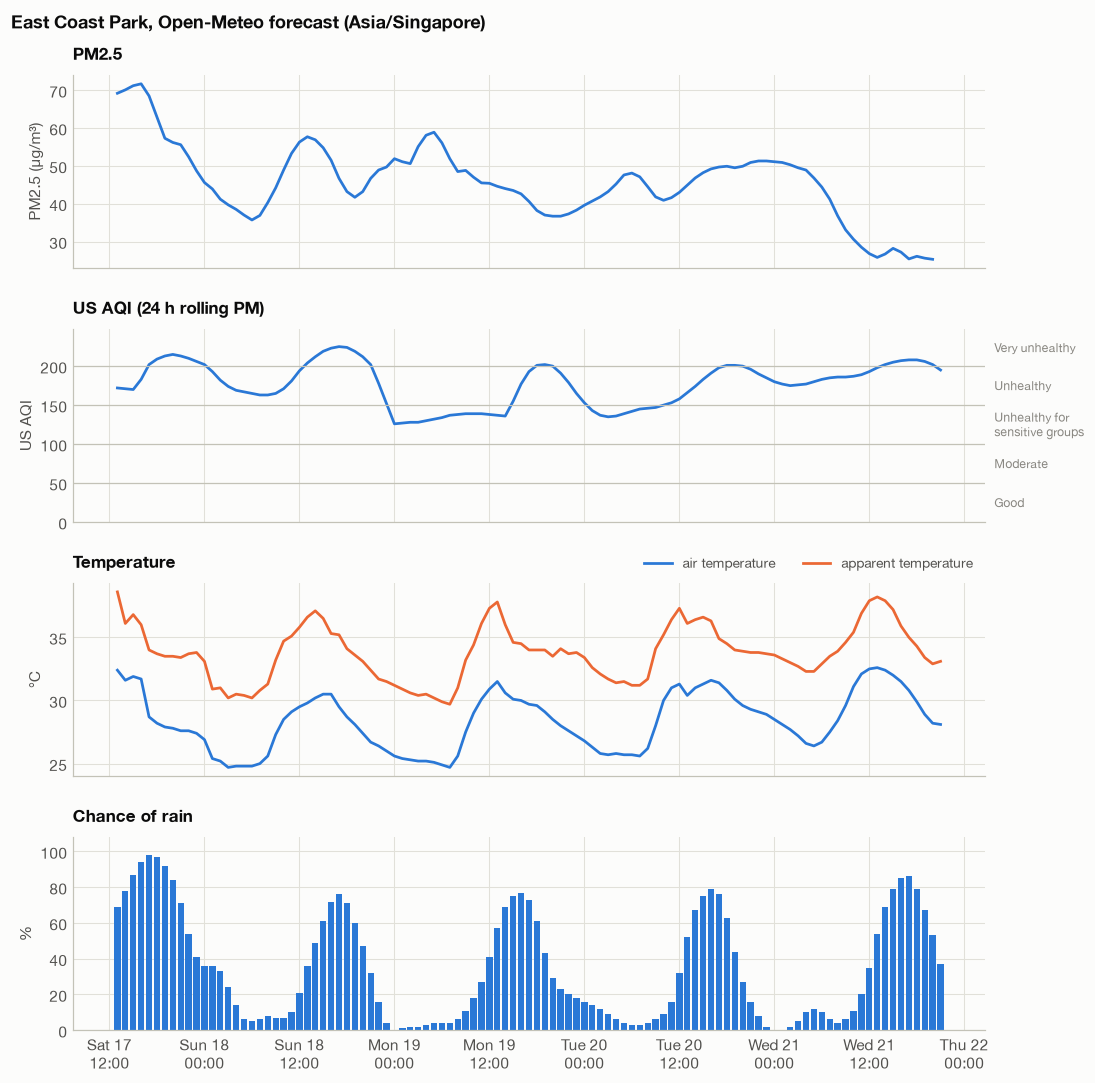

In [8]:
win = tl.loc[now.floor("h"): tl.attrs["aq_horizon"]]
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

ax = axes[0]
ax.plot(win.index, win.pm25_ugm3, color=C[0])
ax.set(ylabel="PM2.5 (µg/m³)", title="PM2.5")

ax = axes[1]
ax.plot(win.index, win.aqi_us, color=C[0])
ax.set(ylabel="US AQI", title="US AQI (24 h rolling PM)", ylim=(0, max(win.aqi_us.max() * 1.1, 110)))
# category bands: boundary hairlines, names in the right margin at each band's middle
lo = 0
for top, name in AQI_CATEGORIES:
    hi = min(top, ax.get_ylim()[1])
    if lo < hi:
        if top < ax.get_ylim()[1]:
            ax.axhline(top, color=AXIS, lw=0.8)
        ax.text(1.01, (lo + hi) / 2, name.replace(" for ", " for\n"), transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=8, color=MUTED, clip_on=False)
    lo = top

ax = axes[2]
ax.plot(win.index, win.temp_c, color=C[0], label="air temperature")
ax.plot(win.index, win.apparent_temp_c, color=C[1], label="apparent temperature")
ax.set(ylabel="°C", title="Temperature")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncols=2)

ax = axes[3]
ax.bar(win.index, win.precip_prob_pct, width=1 / 24 * 0.8, color=C[0])
storm = win[win.thunderstorm]
if len(storm):
    ax.plot(storm.index, [102] * len(storm), "v", ms=6, color=INK2, label="thunderstorm forecast")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0))
ax.set(ylabel="%", ylim=(0, 108), title="Chance of rain")

axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=now.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d\n%H:%M", tz=now.tz))
fig.suptitle(f"East Coast Park, Open-Meteo forecast ({tl.attrs['timezone']})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Limits of the source

These come from the Open-Meteo documentation, not from this notebook:

* The air quality forecast is the CAMS global model on a 0.4° grid (about 45 km). Every point in Singapore shares one
  or two grid cells.
* The air quality horizon is about 4.5 days ahead even when `forecast_days=7` is requested, because the CAMS global
  run is 5 days long. Weather goes out 16 days.
* `us_aqi` uses a 24 h rolling average for PM2.5 and PM10, so it moves more slowly than an hourly reading. For the
  intake calculation in `explore.ipynb`, use `pm25_ugm3` directly: intake (µg) = PM2.5 × VE / 1000 × minutes.
* The free API is for non-commercial use. Commercial use needs an Open-Meteo API key and the `customer-` server prefix.